# What makes one grape's reviews different from another's

Each comparison here is a small model that tries to tell two grapes apart from the review text alone, using logistic regression on TF-IDF. How well it does tells us how different the reviews are, and its weights tell us which words make the difference.

Both sides get the same number of reviews, and the text has grape and place names removed (`descriptor_ngrams`). The functions live in `grape_differences.py`; this notebook runs them and shows the results. Build the data first with `dataset_cleaning.ipynb` and `data_processing.py`.

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import grape_differences as gd

pd.set_option("display.max_columns", 30, "display.max_rows", 100, "display.width", 200)

df = gd.load_reviews()
print(f"{len(df):,} single-grape reviews across {df['grape'].nunique()} grapes")

109,163 single-grape reviews across 27 grapes


## First comparison: Cabernet Sauvignon vs Merlot in California

These two usually get described as similar, so they're a good first test. We repeat the comparison on 5 random samples of the larger grape, to see which words hold up.

In [2]:
row, words = gd.compare_pair(df, "Cabernet Sauvignon", "Merlot", place="California")
pd.Series(row).to_frame("value")

,value
grape_a,Cabernet Sauvignon
grape_b,Merlot
level,province
place_a,California
place_b,California
n_train_per_side,1512
n_val_per_side,320
train_accuracy,0.853
val_accuracy,0.718
val_auc,0.797


In [3]:
def show_words(words, grape, n=15):
    """The strongest words for one side. pct columns are % of each grape's training reviews that use the word."""
    a, b = words["grape_a"].iloc[0], words["grape_b"].iloc[0]
    return (
        words[words["favors_grape"].eq(grape)]
        .head(n)[["term", "in_top_runs", "weight", "pct_a", "pct_b"]]
        .rename(columns={"pct_a": f"% of {a}", "pct_b": f"% of {b}"})
        .reset_index(drop=True)
    )


show_words(words, "Cabernet Sauvignon")

,term,in_top_runs,weight,% of Cabernet Sauvignon,% of Merlot
0,blackberry,5,4.728,48.638,26.521
1,cassis,5,3.841,15.106,3.175
2,black_currant,5,3.165,15.397,2.447
3,currant,5,2.443,30.093,17.196
4,black,5,1.860,30.913,18.585
5,year,5,1.768,18.585,7.077
6,classic,5,1.666,4.577,0.794
7,ripe,5,1.368,20.317,14.286
8,cellar,5,1.336,7.169,1.852
9,could,4,1.529,4.464,1.389


In [4]:
show_words(words, "Merlot")

,term,in_top_runs,weight,% of Cabernet Sauvignon,% of Merlot
0,cherry,5,-4.542,35.992,58.730
1,plum,5,-2.560,8.770,13.492
2,red,5,-2.346,10.767,19.709
3,red_currant,5,-2.187,2.460,7.011
4,dry,5,-1.999,23.452,31.878
5,fruity,5,-1.526,4.034,8.003
6,variety,5,-1.523,1.415,3.175
7,black_cherry,5,-1.450,8.624,11.772
8,sandalwood,5,-1.438,0.688,2.844
9,nice,5,-1.335,3.995,8.267


## How much can we trust this?

Accuracy by itself doesn't say much, so `check_pair` asks a few questions on the validation reviews. How far could the score move? Could it be luck? Is the model equally right about both grapes? And do the top words really explain it, or is the model relying on something else?

For luck, we shuffle the grape labels and retrain 200 times, so the model has nothing real to learn. With 200 shuffles the smallest possible p-value is about 0.005. The test split stays untouched until the very end.

In [5]:
checks = gd.check_pair(df, "Cabernet Sauvignon", "Merlot", place="California")
checks["summary"].to_frame("value")

,value
val_reviews,640.000
accuracy,0.727
accuracy_low,0.691
accuracy_high,0.761
auc,0.799
auc_low,0.767
auc_high,0.832
shuffled_accuracy_mean,0.502
shuffled_accuracy_max,0.561
p_value,0.005


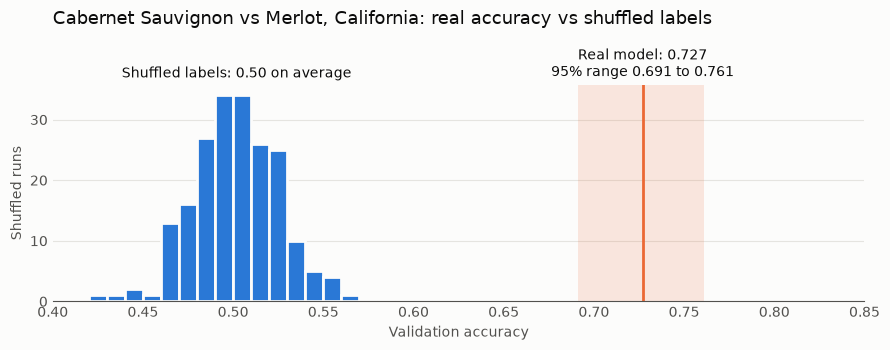

In [6]:
gd.plot_check(checks, "Cabernet Sauvignon vs Merlot, California: real accuracy vs shuffled labels")
plt.show()

In [7]:
display(checks["confusion"])
checks["by_grape"]

,predicted Cabernet Sauvignon,predicted Merlot
true Cabernet Sauvignon,229,91
true Merlot,84,236


,precision,recall,f1,reviews
Cabernet Sauvignon,0.732,0.716,0.724,320
Merlot,0.722,0.738,0.730,320


### Does the method fail when it should?

A check is only worth something if it can fail. Pinot Noir vs Chardonnay should be easy. For the other test we split California Cabernet into two fake grapes at random: there's no real difference to find, so the model should land near 0.50.

In [8]:
rng = np.random.default_rng(4401)
fake = gd.select_side(df, "Cabernet Sauvignon", "California").copy()
fake["grape"] = rng.choice(["Fake A", "Fake B"], size=len(fake))

controls = {
    "Pinot Noir vs Chardonnay (should be easy)": gd.check_pair(df, "Pinot Noir", "Chardonnay", place="California"),
    "Cabernet Sauvignon vs Merlot (the real question)": checks,
    "Cabernet split at random (should be about 0.50)": gd.check_pair(fake, "Fake A", "Fake B", place="California"),
}
pd.DataFrame({name: c["summary"] for name, c in controls.items()}).T[
    ["accuracy", "accuracy_low", "accuracy_high", "shuffled_accuracy_mean", "p_value", "top_words_accuracy"]
]

,accuracy,accuracy_low,accuracy_high,shuffled_accuracy_mean,p_value,top_words_accuracy
Pinot Noir vs Chardonnay (should be easy),0.991,0.987,0.995,0.498,0.005,0.978
Cabernet Sauvignon vs Merlot (the real question),0.727,0.691,0.761,0.502,0.005,0.709
Cabernet split at random (should be about 0.50),0.486,0.455,0.516,0.499,0.826,0.515


### Is the model picking up the reviewer instead of the grape?

If one reviewer wrote most of one grape, the model could be learning their writing style. To test that, we compare groups of reviews at exactly the same size, since a smaller sample scores lower regardless. Each row runs on 30 random samples.

Most of these reviews don't name a taster, so the reviewer check can only cover the ones that do.

In [9]:
california = df[df["province"].eq("California") & df["grape"].isin(["Cabernet Sauvignon", "Merlot"])]
print(f"{california['taster_name'].notna().mean():.1%} of these reviews name a taster")

groups = {
    "All reviews": df,
    "No taster named": df[df["taster_name"].isna()],
    "Taster named (any)": df[df["taster_name"].notna()],
    "Virginie Boone only": df[df["taster_name"].eq("Virginie Boone")],
}
rows = {}
for name, reviews in groups.items():
    row, _ = gd.compare_pair(reviews, "Cabernet Sauvignon", "Merlot", place="California", n_per_side=293, seeds=range(30))
    rows[name] = {k: row[k] for k in ["n_train_per_side", "n_val_per_side", "train_accuracy", "val_accuracy", "val_accuracy_sd", "val_auc"]}
pd.DataFrame(rows).T

29.3% of these reviews name a taster


,n_train_per_side,n_val_per_side,train_accuracy,val_accuracy,val_accuracy_sd,val_auc
All reviews,205.0,44.0,0.913,0.672,0.055,0.735
No taster named,205.0,44.0,0.912,0.718,0.049,0.787
Taster named (any),205.0,44.0,0.910,0.602,0.052,0.646
Virginie Boone only,205.0,44.0,0.921,0.642,0.048,0.707
